## Partie 5 — Détection et traitement des outliers

In [1]:
try:
    import pandas as pd
    import numpy as np
    import statistics
    from matplotlib import pyplot as plt
    print('start working')
except ImportError:
    print('You need to install libraries')

start working


In [2]:
df = pd.read_csv(r'C:\Users\Youss\Documents\IAOADA201\apronfodir les systems decisionelles\seance 10 - synthese\data\commandes_nettoye.csv')
df

,id_commande,date_commande,ville,sexe,age_client,categorie,canal,nb_articles,montant_dh,entrepot,delai_livraison_jours,colis_endommage,satisfaction,retour_client,mois
0,CMD0001,2025-01-01,casablanca,femme,44.0,beaute,application,3.0,210.97,A,2.0,Non,moyen,non,1
1,CMD0002,2025-01-01,tetouan,femme,26.0,mode,web,5.0,579.45,B,5.0,Non,faible,non,1
2,CMD0003,2025-01-03,tanger,homme,28.0,sport,application,2.0,372.35,B,2.0,Non,eleve,non,1
3,CMD0004,2025-01-05,rabat,femme,18.0,mode,application,3.0,478.11,C,4.0,Oui,faible,oui,1
4,CMD0005,2025-01-05,rabat,femme,41.0,electronique,application,7.0,411.04,C,4.0,Non,eleve,non,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,CMD0496,2025-12-30,fes,femme,55.0,maison,web,1.0,469.10,B,2.0,Non,eleve,non,12
496,CMD0497,2025-12-30,tetouan,homme,42.0,beaute,web,2.0,56.07,B,4.0,Non,faible,non,12
497,CMD0498,2025-12-30,rabat,femme,18.0,electronique,web,1.0,693.66,A,4.0,Non,faible,non,12
498,CMD0499,2025-12-30,casablanca,homme,41.0,mode,web,3.0,443.36,A,4.0,Non,moyen,non,12


In [3]:
nums = df.select_dtypes(include=float)
nums.columns

Index(['age_client', 'nb_articles', 'montant_dh', 'delai_livraison_jours'], dtype='str')

In [4]:
for i in nums :
    q1, q3 = df[i].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[i] < q1 - 1.5 * iqr) | (df[i] > q3 + 1.5 * iqr)
    print('Avec 1,5 :' )
    print(f"Pour {i} , Q1 = {q1} , Q3 = {q3} , IQR = {iqr} outliers {mask.sum()}  \n" )
    mask = (df[i] < q1 - 3 * iqr) | (df[i] > q3 + 3 * iqr)
    print('Avec 3 :' )
    print(f"Pour {i} , Q1 = {q1} , Q3 = {q3} , IQR = {iqr} outliers {mask.sum()}  \n" )
    print('-'*100)

Avec 1,5 :
Pour age_client , Q1 = 27.0 , Q3 = 42.0 , IQR = 15.0 outliers 3  

Avec 3 :
Pour age_client , Q1 = 27.0 , Q3 = 42.0 , IQR = 15.0 outliers 2  

----------------------------------------------------------------------------------------------------
Avec 1,5 :
Pour nb_articles , Q1 = 1.0 , Q3 = 3.0 , IQR = 2.0 outliers 8  

Avec 3 :
Pour nb_articles , Q1 = 1.0 , Q3 = 3.0 , IQR = 2.0 outliers 2  

----------------------------------------------------------------------------------------------------
Avec 1,5 :
Pour montant_dh , Q1 = 266.0425 , Q3 = 609.7475 , IQR = 343.7049999999999 outliers 47  

Avec 3 :
Pour montant_dh , Q1 = 266.0425 , Q3 = 609.7475 , IQR = 343.7049999999999 outliers 19  

----------------------------------------------------------------------------------------------------
Avec 1,5 :
Pour delai_livraison_jours , Q1 = 2.0 , Q3 = 4.0 , IQR = 2.0 outliers 4  

Avec 3 :
Pour delai_livraison_jours , Q1 = 2.0 , Q3 = 4.0 , IQR = 2.0 outliers 3  

-------------------------

Tracez deux box plots : (a) montant_dh pour toutes les commandes ; (b) montant_dh par
catégorie, côte à côte. Quels outliers apparaissent par catégorie sans apparaître globalement,
ou l’inverse ? Faut-il détecter globalement ou par groupe ? (Un montant de 2 500 DH est-il
aussi suspect en électronique qu’en beauté ?)

<Axes: title={'center': 'montant_dh'}, xlabel='categorie'>

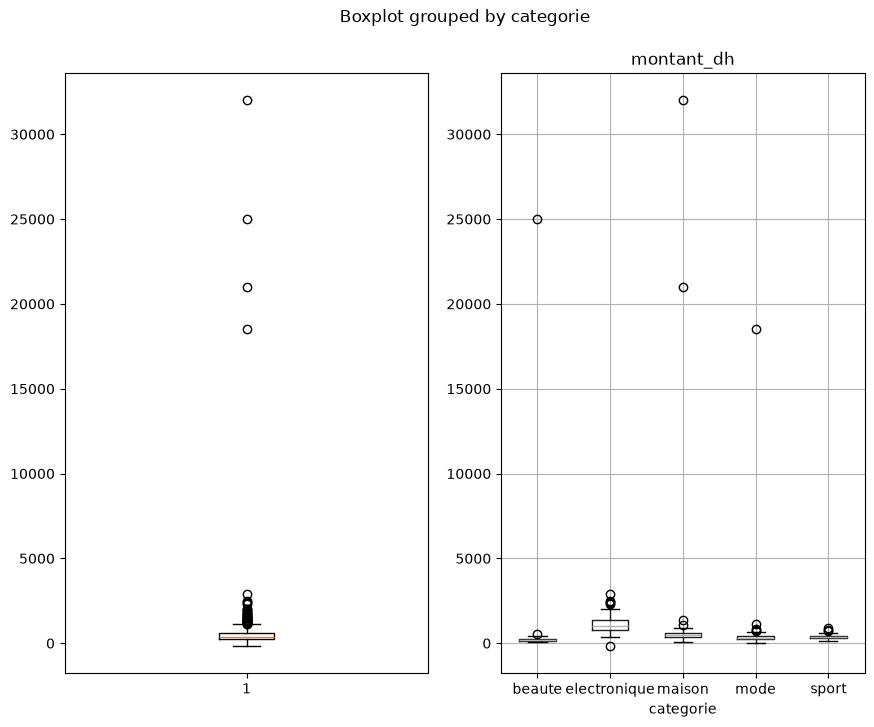

In [5]:
fig , axes = plt.subplots(1,2,figsize=(10,8))

axes[0].boxplot(nums['montant_dh'])
df.boxplot(column='montant_dh' , by='categorie', ax=axes[1])


In [6]:
df['z_montant'] =( df['montant_dh'] - df['montant_dh'].mean()) / df['montant_dh'].std()

df['z_age'] = (df['age_client'] - df['age_client'].mean()) / df['age_client'].std()

In [7]:
outliers_montant = df[abs(df['z_montant'])>3]
outliers_montant

,id_commande,date_commande,ville,sexe,age_client,categorie,canal,nb_articles,montant_dh,entrepot,delai_livraison_jours,colis_endommage,satisfaction,retour_client,mois,z_montant,z_age
108,CMD0109,2025-03-26,tetouan,femme,25.0,maison,application,2.0,32000.0,A,4.0,Non,moyen,non,3,14.260777,-0.870308
206,CMD0207,2025-04-06,casablanca,femme,35.0,mode,web,1.0,18500.0,B,2.0,Non,eleve,non,4,8.109761,0.004901
382,CMD0383,2025-10-06,tanger,femme,38.0,beaute,telephone,1.0,25000.0,B,2.0,Non,eleve,non,10,11.071361,0.267464
398,CMD0399,2025-10-24,tetouan,femme,18.0,maison,application,4.0,21000.0,B,1.0,Non,moyen,oui,10,9.248838,-1.482954


In [8]:
outliers_age = df[abs(df['z_age']) > 3]
outliers_age

,id_commande,date_commande,ville,sexe,age_client,categorie,canal,nb_articles,montant_dh,entrepot,delai_livraison_jours,colis_endommage,satisfaction,retour_client,mois,z_montant,z_age
30,CMD0031,2025-01-22,casablanca,femme,130.0,beaute,web,3.0,116.13,A,4.0,Non,moyen,non,1,-0.266497,8.319384
208,CMD0209,2025-06-06,fes,homme,118.0,mode,web,1.0,15.00,B,3.0,Non,moyen,non,6,-0.312575,7.269133
370,CMD0371,2025-09-28,rabat,femme,0.0,beaute,telephone,1.0,178.88,C,4.0,Non,faible,non,9,-0.237906,-3.058329


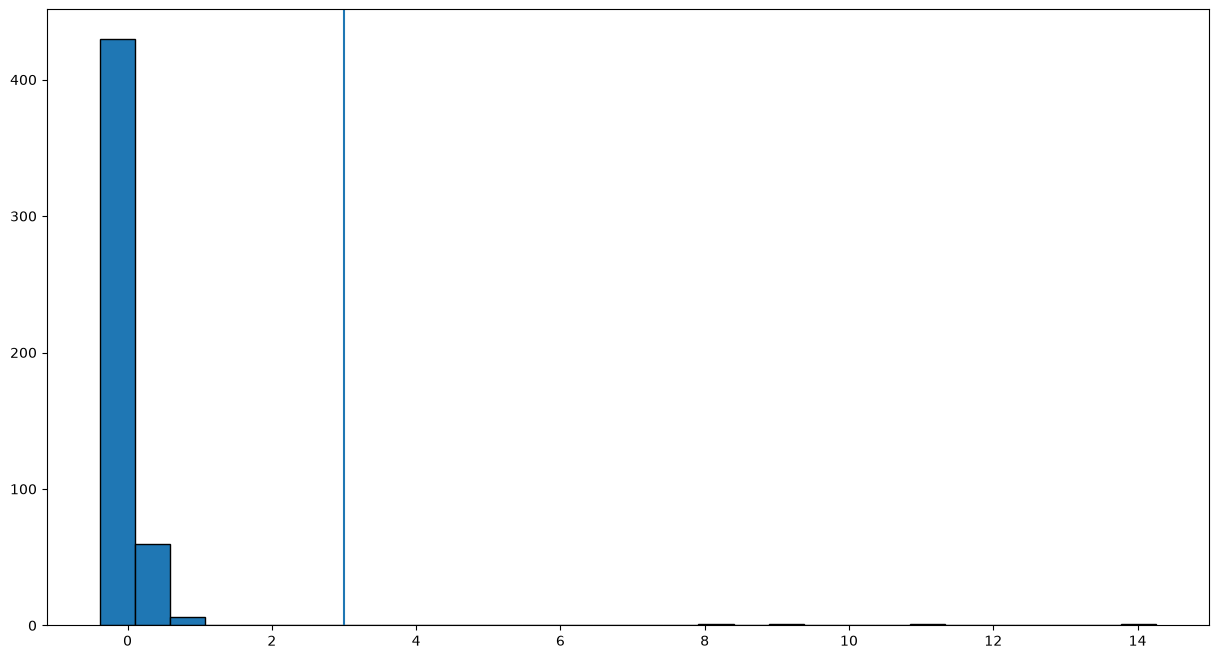

In [13]:
plt.figure(figsize=(15,8))
plt.hist(
    df['z_montant'],
    bins = 30,
    edgecolor='black'
)
plt.axvline(3)


In [18]:
print("Methode de IQR (1,5) :")
i = 'montant_dh'
q1, q3 = df[i].quantile([0.25, 0.75])
iqr = q3 - q1
masque = (df[i] < q1 - 1.5 * iqr) | (df[i] > q3 + 1.5 * iqr)
print(f"les bornes sont :({q1 - 1.5 * iqr} ; {q3 + 1.5 * iqr}) ")
print(i, masque.sum(), "outliers")
print('-' * 59)
print("Methode de IQR (3) :")
i = 'montant_dh'
q1, q3 = df[i].quantile([0.25, 0.75])
iqr = q3 - q1
masque = (df[i] < q1 - 3* iqr) | (df[i] > q3 + 3 * iqr)
print(f"les bornes sont :({q1 - 3 * iqr} ; {q3 + 3 * iqr}) ")
print(i, masque.sum(), "outliers")
print('-' * 59)
print("Methode des deux ecart types :")
ecart = np.std(df['montant_dh'])
moyenne = np.mean(df['montant_dh'])
masque = (df['montant_dh'] < moyenne - 2 * ecart ) | (df['montant_dh'] >  moyenne + 2 * ecart)
print(f"les bornes sont : ({moyenne - 2 * ecart} ; {moyenne + 2 * ecart})")
print("montant_dh ", masque.sum(), "outliers")
print('-' * 59)
print('methode de z_score :')
ecart_montant = np.std(df['montant_dh'])
moyenne_montant = np.mean(df['montant_dh'])
z_scores = (df['montant_dh'] - moyenne_montant) / ecart_montant
z_score_outlier = (np.abs(z_scores) > 3).sum()
print("les bornes sont  (-3 ; 3)")
print(f"montant_dh {z_score_outlier} outliers")

Methode de IQR (1,5) :
les bornes sont :(-249.51499999999987 ; 1125.3049999999998) 
montant_dh 47 outliers
-----------------------------------------------------------
Methode de IQR (3) :
les bornes sont :(-765.0724999999998 ; 1640.8624999999997) 
montant_dh 19 outliers
-----------------------------------------------------------
Methode des deux ecart types :
les bornes sont : (-3684.0995608770127 ; 5086.154120877013)
montant_dh  4 outliers
-----------------------------------------------------------
methode de z_score :
les bornes sont  (-3 ; 3)
montant_dh 4 outliers
